# Redshift convergence of cloelib's Limber $C_\ell$

**Question.** In `studies/euclid_dr3/time_comparison_Euclid_DR3.ipynb`, cloelib's $C_\ell$ changed by up to 6.5% between `N_Z = 100` and `250` redshift points, and erratically, while pyccl, CosmoSIS and former CLOE changed by 0.5–1% on identical inputs. The largest offender was GG for SPV3 bin 1, the narrowest, lowest-$z$ bin.

**Approach.** cloelib uses two redshift grids:
- the **tracer grid** `n_t`, used for the n(z), the window functions and the Limber integral;
- the **perturbation grid** `n_p`, used for CAMB's $P(k,z)$ and FAST-PT growth, interpolated onto the tracer grid with akima in $\log P$.

The benchmark set them equal. Here they are varied separately (`run_experiments.py`, `zconv_common.py`):

| experiment | varied | fixed | isolates |
|---|---|---|---|
| E1 | `n_t` = 100 … 3201, odd and even; Simpson vs trapezoid weights | `n_p` = 255 | Limber + window-function quadrature |
| E2 | `n_p` = 50 … 255, odd and even | `n_t` = 1601 | redshift sampling of $P(k,z)$ |
| E3 | as E2, with signed spectra interpolated in $P$ instead of $\log|P|$ | | `Pkl_interp_signed` |
| E0 | `n_t` = `n_p` = N | | the benchmark's coupled set-up |
| E4–E6 | non-linear bias: P-interpolation, bias terms off, $\sigma^4$ off | `n_p` = 255 | which term causes the slow convergence (section 4) |

**Reference.** For each model, E1 at `n_t = 3201` with Simpson weights and `n_p = 255`. All errors are $\max_{\ell>20}|C_\ell/C_\ell^{\rm ref}-1|$ on the six check spectra of the benchmark.

**Models:**
- `linear_NLA` and `linear_TATT`: polynomial bias with $b=1$; these run on `main`.
- `nlbias_NLA` and `nlbias_TATT`: the McDonald & Roy non-linear bias. These run on the `384` branch, and `nlbias_TATT` is the benchmark model.

In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

HERE = Path('.').resolve()
(HERE / 'figures').mkdir(exist_ok=True)   # figures are not tracked in git
R = {}
for f in sorted(glob.glob(str(HERE / 'results/results_*.npz'))):
    d = np.load(f)
    R.update({k: d[k] for k in d.files})
ELLS = R['ells']
MASK = ELLS > 20
SPECTRA = ['GG_1_1', 'GG_7_7', 'GE_3_11', 'EE_1_1', 'EE_7_13', 'EE_13_13']
MODELS = [m for m in ('linear_NLA', 'linear_TATT', 'nlbias_NLA', 'nlbias_TATT') if any(f'|{m}|' in k for k in R)]
print('models found:', MODELS, '|', len(R) - 1, 'arrays')


def spec(tag, model, setting, n_t, n_p, key):
    return R[f'{tag}|{model}|{setting}|nt={n_t}|np={n_p}|{key}']


def err(a, b):
    return 100 * np.max(np.abs(a[MASK] / b[MASK] - 1))


def ref(model, key):
    return spec('E1', model, 'simpson', 3201, 255, key)


def grid_values(tag, model, setting):
    vals = sorted({(int(k.split('|')[3][3:]), int(k.split('|')[4][3:])) for k in R
                   if k.startswith(f'{tag}|{model}|{setting}|')})
    return vals


# Is the reference itself converged? Simpson at 3201 vs trapezoid at 3200, and Simpson 3201 vs 1601
print('\nReference check: max |C/C_ref - 1| [%]')
print(f'{"model":13s} ' + ' '.join(f'{k:>9s}' for k in SPECTRA))
for m in MODELS:
    t = [err(spec('E1', m, 'trapezoid', 3200, 255, k), ref(m, k)) for k in SPECTRA]
    s = [err(spec('E1', m, 'simpson', 1601, 255, k), ref(m, k)) for k in SPECTRA]
    print(f'{m:13s} ' + ' '.join(f'{v:9.4f}' for v in t) + '   (trapezoid 3200)')
    print(f'{"":13s} ' + ' '.join(f'{v:9.4f}' for v in s) + '   (Simpson 1601)')

models found: ['linear_NLA', 'linear_TATT', 'nlbias_NLA', 'nlbias_TATT'] | 1903 arrays

Reference check: max |C/C_ref - 1| [%]
model            GG_1_1    GG_7_7   GE_3_11    EE_1_1   EE_7_13  EE_13_13
linear_NLA       0.0001    0.0007    0.0001    0.0003    0.0001    0.0000   (trapezoid 3200)
                 0.0008    0.0013    0.0005    0.0015    0.0002    0.0001   (Simpson 1601)
linear_TATT      0.0001    0.0007    0.0001    0.0056    0.0001    0.0000   (trapezoid 3200)
                 0.0008    0.0013    0.0005    0.0125    0.0002    0.0001   (Simpson 1601)
nlbias_NLA       0.0027    0.0007    0.0001    0.0003    0.0001    0.0000   (trapezoid 3200)
                 0.0105    0.0013    0.0005    0.0015    0.0002    0.0001   (Simpson 1601)
nlbias_TATT      0.0027    0.0007    0.0001    0.0056    0.0001    0.0000   (trapezoid 3200)
                 0.0105    0.0013    0.0005    0.0125    0.0002    0.0001   (Simpson 1601)


## 1. The quadrature alone (E1): tracer grid varied, $P(k,z)$ grid fixed

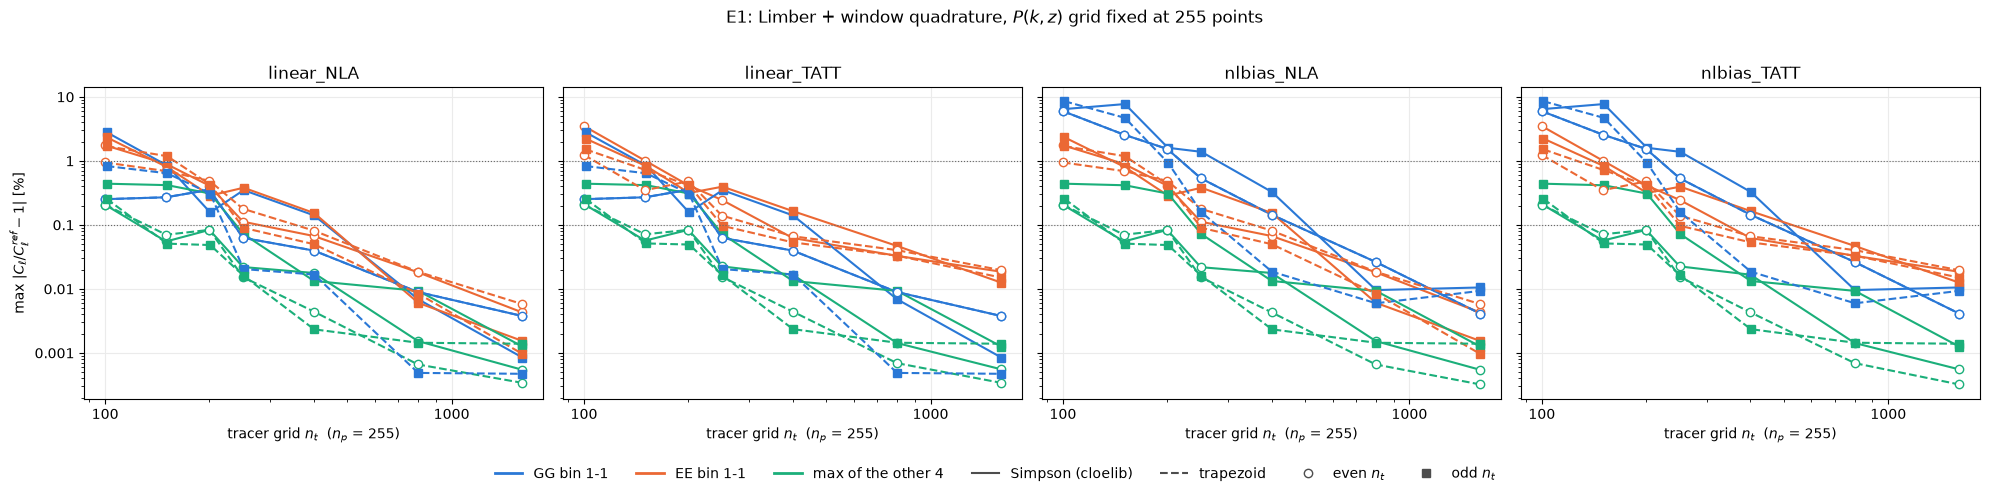

In [2]:
COLS = {'GG_1_1': '#2a78d6', 'EE_1_1': '#eb6834', 'others': '#1baf7a'}
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.4), sharey=True, squeeze=False)
for ax, m in zip(axes[0], MODELS):
    for quad, ls in (('simpson', '-'), ('trapezoid', '--')):
        nts = [nt for nt, _ in grid_values('E1', m, quad) if nt < 3200]
        for parity, mk in ((0, 'o'), (1, 's')):
            sel = [nt for nt in nts if nt % 2 == parity]
            for key, col in (('GG_1_1', COLS['GG_1_1']), ('EE_1_1', COLS['EE_1_1'])):
                ax.plot(sel, [err(spec('E1', m, quad, nt, 255, key), ref(m, key)) for nt in sel], color=col, ls=ls,
                        marker=mk, ms=6, mfc=col if parity else 'white', lw=1.5)
            others = [max(err(spec('E1', m, quad, nt, 255, k), ref(m, k)) for k in SPECTRA if k not in ('GG_1_1', 'EE_1_1'))
                      for nt in sel]
            ax.plot(sel, others, color=COLS['others'], ls=ls, marker=mk, ms=6, mfc=COLS['others'] if parity else 'white', lw=1.5)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.axhline(1, color='0.4', lw=0.8, ls=':'); ax.axhline(0.1, color='0.4', lw=0.8, ls=':')
    ax.set_title(m, fontsize=12); ax.set_xlabel('tracer grid $n_t$  ($n_p$ = 255)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.grid(True, which='major', color='0.92')
axes[0, 0].set_ylabel('max $|C_\\ell/C_\\ell^{ref}-1|$ [%]')
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=COLS['GG_1_1'], lw=2, label='GG bin 1-1'),
           Line2D([], [], color=COLS['EE_1_1'], lw=2, label='EE bin 1-1'),
           Line2D([], [], color=COLS['others'], lw=2, label='max of the other 4'),
           Line2D([], [], color='0.3', ls='-', label='Simpson (cloelib)'),
           Line2D([], [], color='0.3', ls='--', label='trapezoid'),
           Line2D([], [], color='0.3', marker='o', mfc='white', ls='none', label='even $n_t$'),
           Line2D([], [], color='0.3', marker='s', ls='none', label='odd $n_t$')]
fig.legend(handles=handles, loc='lower center', ncol=7, frameon=False, bbox_to_anchor=(0.5, -0.08), fontsize=10)
fig.suptitle('E1: Limber + window quadrature, $P(k,z)$ grid fixed at 255 points', y=1.02)
plt.tight_layout(); plt.savefig('figures/E1_quadrature.png', dpi=140, bbox_inches='tight'); plt.show()

**E1 result.** With the $P(k,z)$ grid fixed, the tracer-grid quadrature behaves differently for the two bias models and the two parities of `n_t`:
- **Linear-bias models, even `n_t`:** convergence is smooth: GG 1-1 within about 0.25% at `n_t = 100`, and below 0.1% from 250.
- **Odd `n_t`:** the error jumps, for example GG 1-1 to 2.8% at 101 and 0.8% at 151.
  - cloelib's Simpson rule for **even** N is the average of two Simpson rules shifted by one node, so its interior weights are exactly 1: a trapezoid rule.
  - For **odd** N it is the true composite Simpson rule, with weights alternating 4/3, 2/3. On the narrow bin-1 $n(z)^2$ peak, which spans only about 3 nodes per standard deviation at `n_t = 100`, the result then depends on where the peak falls between nodes.
  - The trapezoid rule (dashed) has no parity effect.
- **Non-linear-bias GG 1-1:** about 6% at 100, decreasing slowly for both parities. Section 4 shows this is not a quadrature problem.

## 2. The $P(k,z)$ redshift sampling (E2, E3): perturbation grid varied, tracer grid fixed at 1601

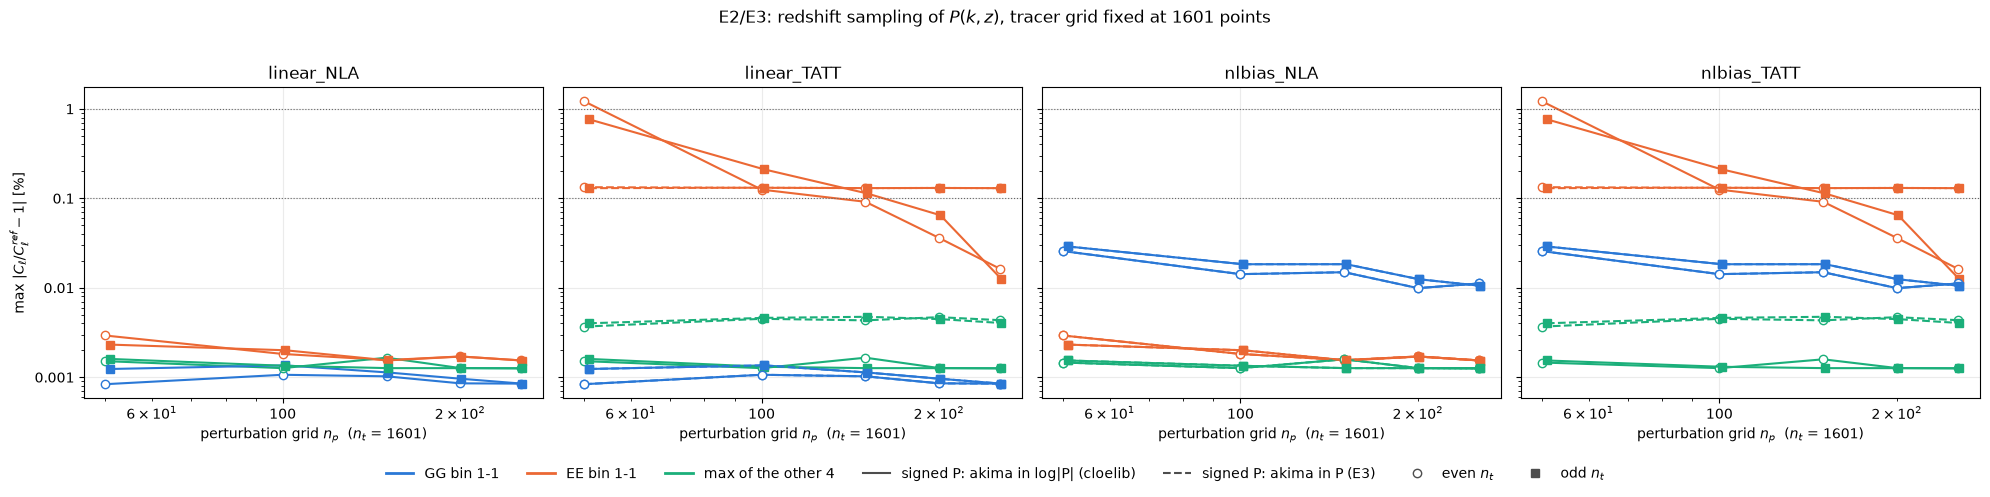

In [3]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.4), sharey=True, squeeze=False)
for ax, m in zip(axes[0], MODELS):
    for tag, setting, ls in (('E2', 'logabs', '-'), ('E3', 'linear_p', '--')):
        nps = [np_ for _, np_ in grid_values(tag, m, setting)]
        if not nps:
            continue
        for parity, mk in ((0, 'o'), (1, 's')):
            sel = [n for n in nps if n % 2 == parity]
            for key, col in (('GG_1_1', COLS['GG_1_1']), ('EE_1_1', COLS['EE_1_1'])):
                ax.plot(sel, [err(spec(tag, m, setting, 1601, n, key), ref(m, key)) for n in sel], color=col, ls=ls,
                        marker=mk, ms=6, mfc=col if parity else 'white', lw=1.5)
            others = [max(err(spec(tag, m, setting, 1601, n, k), ref(m, k)) for k in SPECTRA if k not in ('GG_1_1', 'EE_1_1'))
                      for n in sel]
            ax.plot(sel, others, color=COLS['others'], ls=ls, marker=mk, ms=6, mfc=COLS['others'] if parity else 'white', lw=1.5)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.axhline(1, color='0.4', lw=0.8, ls=':'); ax.axhline(0.1, color='0.4', lw=0.8, ls=':')
    ax.set_title(m, fontsize=12); ax.set_xlabel('perturbation grid $n_p$  ($n_t$ = 1601)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.grid(True, which='major', color='0.92')
axes[0, 0].set_ylabel('max $|C_\\ell/C_\\ell^{ref}-1|$ [%]')
handles = handles[:3] + [Line2D([], [], color='0.3', ls='-', label='signed P: akima in log|P| (cloelib)'),
                         Line2D([], [], color='0.3', ls='--', label='signed P: akima in P (E3)')] + handles[5:]
fig.legend(handles=handles, loc='lower center', ncol=7, frameon=False, bbox_to_anchor=(0.5, -0.08), fontsize=10)
fig.suptitle('E2/E3: redshift sampling of $P(k,z)$, tracer grid fixed at 1601 points', y=1.02)
plt.tight_layout(); plt.savefig('figures/E2_E3_pk_sampling.png', dpi=140, bbox_inches='tight'); plt.show()

**E2/E3 result.** The redshift sampling of $P(k,z)$ is not the cause:
- **GG:** varying the perturbation grid from 50 to 255 points changes GG by at most 0.03%, for every model.
- **EE 1-1 with TATT:** this is the one spectrum that needs a finer $P(k,z)$ grid: 1.2% at `n_p = 50`, 0.2% at 100, 0.06% at 200. The TATT spectra are interpolated in $z$ like everything else, but they change faster.
- **E3:** interpolating the signed spectra in $P$ instead of $\log|P|$ does not converge faster. It settles about 0.13% away from the $\log|P|$ result, and that offset is the same at every `n_p`. So it is a property of the interpolation along $k$ (211 nodes), not of the redshift sampling.

## 3. The benchmark's coupled set-up (E0): `n_t = n_p = N`
The **true** error against the converged reference, and the benchmark's **self-convergence** measure (each N against N = 255 of the same set-up).

In [4]:
print('E0, true error  max |C(N)/C_ref - 1| [%]   (reference: n_t = 3201, n_p = 255)')
for m in MODELS:
    Ns = [n for n, _ in grid_values('E0', m, 'coupled')]
    print(f'\n{m}')
    print(f'{"N":>5s} ' + ' '.join(f'{k:>9s}' for k in SPECTRA) + f' {"self-conv.":>11s}')
    for n in Ns:
        row = [err(spec('E0', m, 'coupled', n, n, k), ref(m, k)) for k in SPECTRA]
        selfc = max(err(spec('E0', m, 'coupled', n, n, k), spec('E0', m, 'coupled', 255, 255, k)) for k in SPECTRA)
        print(f'{n:5d} ' + ' '.join(f'{v:9.3f}' for v in row) + f' {selfc:11.3f}')

E0, true error  max |C(N)/C_ref - 1| [%]   (reference: n_t = 3201, n_p = 255)

linear_NLA
    N    GG_1_1    GG_7_7   GE_3_11    EE_1_1   EE_7_13  EE_13_13  self-conv.
  100     0.252     0.206     0.143     1.753     0.205     0.072       1.568
  101     2.801     0.440     0.110     2.334     0.305     0.087       2.966
  150     0.270     0.043     0.052     0.896     0.055     0.014       1.068
  151     0.846     0.418     0.065     0.799     0.080     0.042       0.668
  200     0.354     0.084     0.014     0.410     0.026     0.020       0.314
  201     0.156     0.309     0.040     0.287     0.079     0.023       0.268
  250     0.063     0.010     0.022     0.112     0.022     0.003       0.313
  251     0.350     0.072     0.056     0.381     0.021     0.008       0.606
  255     0.179     0.106     0.017     0.269     0.013     0.016       0.000

linear_TATT
    N    GG_1_1    GG_7_7   GE_3_11    EE_1_1   EE_7_13  EE_13_13  self-conv.
  100     0.252     0.206     0.143    

**E0 result.** The coupled set-up of the benchmark reproduces its numbers. The non-linear-bias GG 1-1 is 6.0, 2.6, 1.5 and 0.5% from the converged reference at N = 100, 150, 200, 250, and odd N is worse. The linear-bias models stay within 0.35% for even N.

The "self-conv." column is the benchmark's measure: each N against N = 255 of the same set-up. It reproduces the 4.4% of the per-spectrum test in the timing notebook.

## 4. What makes the non-linear-bias GG converge slowly? (E4, E5, E6)
- **E4:** the E1 sweep for the non-linear-bias models with every signed spectrum interpolated in $P$ instead of $\log|P|$. That includes the 384 branch's batched `Pkl_interp_signed_vmap_terms`, which is built at import from the original function object and so has to be replaced separately.
- **E5:** bias terms switched off one at a time.
- **E6:** cloelib's $\sigma^4$ subtraction switched off (`NoSig4LoopComputer`).

In [5]:
for f, title in (('results/results_384_nlbias_NLA_E5.npz', 'E5: bias terms switched off one at a time'),
                 ('results/results_384_nlbias_NLA_E6.npz', 'E6: sigma^4 subtraction on / off')):
    d = np.load(f)
    variants = sorted({k.split('|')[1] for k in d.files if '|' in k}, key=lambda v: list(d.files).index(f'{d.files[1].split("|")[0]}|{v}|nt=100|GG_1_1') if f'{d.files[1].split("|")[0]}|{v}|nt=100|GG_1_1' in d.files else 0)
    tag = d.files[1].split('|')[0]
    nts = sorted({int(k.split('|')[2][3:]) for k in d.files if '|' in k})
    print(f'\n{title}: GG_1_1 error vs the same variant at n_t = {nts[-1]} [%]')
    print(f'{"variant":30s} ' + ' '.join(f'{n:>7d}' for n in nts[:-1]))
    for v in variants:
        r = d[f'{tag}|{v}|nt={nts[-1]}|GG_1_1']
        print(f'{v:30s} ' + ' '.join(f'{err(d[f"{tag}|{v}|nt={n}|GG_1_1"], r):7.3f}' for n in nts[:-1]))

E4 = {}
for f in glob.glob('results/results_384_*_E4.npz'):
    E4.update({k: v for k, v in np.load(f).items()})
print('\nE4 (non-linear bias, signed spectra interpolated in P): GG_1_1 error vs own n_t = 3201 [%]')
for m in ('nlbias_NLA', 'nlbias_TATT'):
    nts = (100, 101, 150, 151, 200, 250, 400, 800)
    print(f'  {m:12s} log|P| (cloelib): ' + ' '.join(f'{err(spec("E1", m, "simpson", n, 255, "GG_1_1"), ref(m, "GG_1_1")):6.2f}' for n in nts))
    print(f'  {"":12s} P              : ' + ' '.join(f'{err(E4[f"E4|{m}|linear_p|nt={n}|np=255|GG_1_1"], E4[f"E4|{m}|linear_p|nt=3201|np=255|GG_1_1"]):6.2f}' for n in nts))


E5: bias terms switched off one at a time: GG_1_1 error vs the same variant at n_t = 3201 [%]
variant                            100     150     200     250     400     800
all terms                        5.973   2.568   1.537   0.535   0.144   0.026
bk2 = 0                          1.660   0.962   0.723   0.206   0.073   0.014
b2 = bs2 = b3nl = 0              0.261   0.270   0.354   0.063   0.040   0.009
b1 only                          0.252   0.270   0.354   0.063   0.040   0.009

E6: sigma^4 subtraction on / off: GG_1_1 error vs the same variant at n_t = 3201 [%]
variant                            100     101     150     151     200     250     400     800
sigma4 subtracted (cloelib)      5.973   6.444   2.568   7.715   1.537   0.535   0.144   0.026
no sigma4                        0.256   2.811   0.255   0.810   0.349   0.061   0.039   0.009
no sigma4, bk2 = 0               0.256   2.810   0.265   0.840   0.349   0.063   0.039   0.009

E4 (non-linear bias, signed spectra interpo

**Result. The slow, erratic convergence of the non-linear-bias GG is not a quadrature or interpolation error.**
- **E4:** interpolating the signed spectra in $P$ instead of $\log|P|$ leaves the errors essentially unchanged (5.8 instead of 6.0% at `n_t = 100`).
- **E5:** $b_1$ alone, or $b_1$ with $b_{k^2}$, converges exactly like linear bias. The errors appear only with $b_2$, $b_{s^2}$ and $b_{3\rm nl}$, the terms that carry cloelib's subtracted $\sigma^4$ constants.
- **E6:** with the $\sigma^4$ kernel set to zero, the non-linear-bias GG converges like linear bias: 0.26% at `n_t = 100`, 0.06% at 250, and the same odd-`n_t` spikes.
- **4.1:** with the $\sigma^4$ terms subtracted, GG 1-1 falls to 75% of its no-$\sigma^4$ value at $\ell \approx 730$ and **changes sign between $\ell = 2369$ and $2999$**. Every large relative error is attained at $\ell = 2369$, next to the crossing. Against $|C_\ell|$ without $\sigma^4$ the same differences are 0.27%, 0.25%, 0.35% and 0.06% at `n_t` = 100, 150, 200, 250. That is the same as linear bias, and as pyccl / CosmoSIS / CLOE.

So the 6.5% in `time_comparison_Euclid_DR3.ipynb` is mostly a relative error measured on a spectrum that passes through zero. Only cloelib subtracts $\sigma^4$, so only cloelib's GG 1-1 did. The other codes' spectra do not cross zero.

### 4.1. The relative error is dominated by a zero crossing of $C_\ell$
With cloelib's $\sigma^4$ subtraction, GG 1-1 changes sign at high $\ell$, so $|C_\ell/C_\ell^{\rm ref}-1|$ is ill-conditioned there.
The cell compares that relative error with the same difference measured against a scale that does not vanish, $|C_\ell|$ without $\sigma^4$.

GG_1_1 with sigma^4 subtracted changes sign between ell = ['2369-2999']
C(sigma^4 subtracted) / C(no sigma^4) at ell = [   7   69  728 1871 2999] -> [ 0.994  0.98   0.75   0.266 -0.266]

  n_t  max|dC/C_ref| [%]  max|dC|/|C_no-sig4| [%]  ell of max rel. error
  100              5.973                    0.274                   2369
  101              6.444                    2.786                   2369
  150              2.568                    0.252                   2369
  151              7.715                    0.802                   2369
  200              1.537                    0.345                   2369
  250              0.535                    0.060                   2369
  400              0.144                    0.039                   2369
  800              0.026                    0.009                   2369


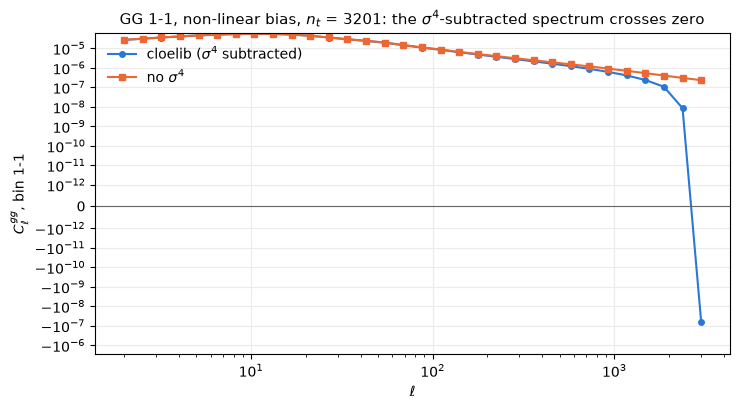

In [6]:
d = np.load('results/results_384_nlbias_NLA_E6.npz')
sub = lambda n: d[f'E6|sigma4 subtracted (cloelib)|nt={n}|GG_1_1']
nos = lambda n: d[f'E6|no sigma4|nt={n}|GG_1_1']
ref_s, scale = sub(3201), np.abs(nos(3201))
cross = np.where(np.diff(np.sign(ref_s)))[0]
print('GG_1_1 with sigma^4 subtracted changes sign between ell =', [f'{ELLS[i]:.0f}-{ELLS[i + 1]:.0f}' for i in cross])
print('C(sigma^4 subtracted) / C(no sigma^4) at ell =', np.round(ELLS[[5, 15, 25, 29, 31]]).astype(int), '->',
      np.round(ref_s[[5, 15, 25, 29, 31]] / nos(3201)[[5, 15, 25, 29, 31]], 3))
print(f'\n{"n_t":>5s} {"max|dC/C_ref| [%]":>18s} {"max|dC|/|C_no-sig4| [%]":>24s} {"ell of max rel. error":>22s}')
for n in (100, 101, 150, 151, 200, 250, 400, 800):
    rel = np.abs(sub(n)[MASK] / ref_s[MASK] - 1)
    absn = np.abs(sub(n)[MASK] - ref_s[MASK]) / scale[MASK]
    print(f'{n:5d} {100 * rel.max():18.3f} {100 * absn.max():24.3f} {ELLS[MASK][rel.argmax()]:22.0f}')

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(ELLS, ref_s, color='#2a78d6', marker='o', ms=4, label='cloelib ($\\sigma^4$ subtracted)')
ax.plot(ELLS, nos(3201), color='#eb6834', marker='s', ms=4, label='no $\\sigma^4$')
ax.axhline(0, color='0.4', lw=0.8)
ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1e-12)
ax.set_xlabel('$\\ell$'); ax.set_ylabel('$C_\\ell^{gg}$, bin 1-1')
ax.set_title('GG 1-1, non-linear bias, $n_t$ = 3201: the $\\sigma^4$-subtracted spectrum crosses zero', fontsize=11)
ax.legend(frameon=False); ax.grid(True, color='0.92')
plt.tight_layout(); plt.savefig('figures/GG11_zero_crossing.png', dpi=140, bbox_inches='tight'); plt.show()

## 5. The stacked Simpson weights of the window functions
`cloelib.auxiliary.math_utils.stacked_simpson(n)` gives, in row $i$, the weights for integrating from node $i$ to the last node. They are used for the lensing efficiency (`ShearTracer.get_lensing_efficiency`) and the magnification efficiency (`PositionsTracer.get_magnification_efficiency`). For a constant integrand, row $i$ should sum to $n-1-i$ grid steps.

In [7]:
import sys
sys.path.insert(0, 'scripts')
import zconv_common as zc
w, sums, exact = zc.stacked_weights_report(6)
np.set_printoptions(precision=3, suppress=True)
print('stacked_simpson(6):\n', w)
print('row sums:', sums, '\nexact:   ', exact)

stacked_simpson(6):
 [[0.417 1.083 1.    1.    1.083 0.417]
 [0.    0.333 1.333 0.667 1.333 0.333]
 [0.    0.    0.417 1.083 1.083 0.417]
 [0.    0.    0.    0.333 1.333 0.333]
 [0.    0.    0.    0.    0.667 0.667]
 [0.    0.    0.    0.    0.    0.333]]
row sums: [5.    4.    3.    2.    1.333 0.333] 
exact:    [5. 4. 3. 2. 1. 0.]


**Result.** The rows for the last two nodes are wrong:
- **Two remaining points:** weights 2/3, 2/3, so a constant integrand sums to 4/3 grid steps instead of 1.
- **One remaining point:** weight 1/3, where the integral over a zero-width interval should be 0.

`stack_zeros_and_simpson` builds these rows with `simpsons_weights_even(2)` and `simpsons_weights_odd(1)`, which do not reduce to the trapezoid rule and to zero.

The error only affects the lensing and magnification efficiency at the highest one or two redshift nodes, where the source $n(z)$ above them vanishes for these bins, so its effect on these spectra is below what the experiments here can resolve. It is still a bug: for a survey whose $n(z)$ extends to the edge of the redshift grid it would bias the high-$z$ efficiency.

## 6. Findings and suggested fixes

| # | finding | severity | where | suggested fix (for this branch) |
|---|---|---|---|---|
| 1 | The large, erratic GG 1-1 "non-convergence" of the benchmark is a **zero crossing of $C_\ell$**: the $\sigma^4$-subtracted non-linear-bias GG changes sign between $\ell \approx 2370$ and 3000, which inflates the relative error. The actual integration error is ≤ 0.35% for even N ≥ 100, the same as linear bias and the other codes | not a numerical bug | — | none in the integrator. Physics question for the bias-model authors: is a negative $C^{gg}_\ell$ at $\ell \sim 3000$ expected for these (illustrative) bias values with the $\sigma^4$ subtraction? |
| 2 | **Odd N uses the true composite Simpson rule** (alternating 4/3, 2/3), which is node-placement sensitive on an under-resolved peaked integrand. GG 1-1 error is 2.8% at N = 101 and 0.8% at 151, against 0.25% at 100 and 150. Even N is effectively the trapezoid rule | real, moderate, avoidable | `math_utils.simpsons_weights_odd` via `simpsons_weights_jit`, used by the Limber integral in `AngularTwoPoint` | use the same rule for both parities: the averaged (even-N) form, or the trapezoid rule. Alternatively document that N_Z should be even. Add a regression test: GG 1-1 at N = 101 vs 100 vs a dense reference |
| 3 | **Stacked Simpson weights are wrong for the last two rows**: 1 point gives weight 1/3 (should be 0); 2 points give 2/3, 2/3 (should be 1/2, 1/2) | real, small for these bins | `math_utils.stack_zeros_and_simpson` / `stacked_simpson` (lensing and magnification efficiency) | special-case rows with 1 and 2 points; unit test that row sums equal the number of remaining intervals |
| 4 | **`cached_stacked_simpson` is `jax.jit` around `functools.lru_cache`**, which caches a tracer. After `jax.clear_caches()`, or any re-trace for the same n, it raises `UnexpectedTracerError` | latent | `math_utils.cached_stacked_simpson` | build the weights with numpy (they depend only on n) and cache the concrete array, without `jit` |
| 5 | TATT EE in the lowest bin needs a finer $P(k,z)$ redshift grid: 1.2% at `n_p = 50`, 0.2% at 100, 0.06% at 200 | resolution guidance | — | document a minimum `n_p` (≳ 150) for TATT, or interpolate the TATT spectra in a variable that varies slowly in $z$ |
| 6 | Monkeypatching the signed interpolation needs two attributes on the 384 branch: `Pkl_interp_signed_vmap_terms` captures `Pkl_interp_signed_vmap` at import | code-structure note | `angular_two_point.py` (384) | none needed; relevant only for tests that swap the interpolator |

**For the timing comparison:** at even N_Z, cloelib's redshift integration is as accurate as pyccl's, CosmoSIS's and former CLOE's. Its larger "self-convergence" there came from finding 1, plus finding 2 at the odd N = 255 used as a reference in the per-spectrum test.